# Exploration des données DVF — 10 régions, 2021-2025

Objectif du notebook : comprendre la structure réelle des fichiers DVF géolocalisés avant de
les nettoyer, justifier chaque règle de nettoyage, puis explorer les prix et les volumes.

* **Source** : Demandes de valeurs foncières géolocalisées (Etalab, à partir des données DGFiP),
  un fichier CSV compressé par année et par département.
* **Périmètre** : les 10 régions les plus peuplées (Île-de-France, Auvergne-Rhône-Alpes,
  Nouvelle-Aquitaine, Occitanie, Hauts-de-France, Grand Est, Provence-Alpes-Côte d'Azur, Pays de la
  Loire, Bretagne, Normandie), soit 77 départements. L'Alsace-Moselle n'est pas couverte par DVF.
* **Prérequis** : `python run.py download clean analyze` (les fichiers bruts et le Parquet nettoyé
  sont lus depuis `data/`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from src import analyze as az
from src.clean import RAW_DTYPES, load_raw
from src.settings import load_config

az.ensure_browser()
pio.renderers.default = "png"        # images statiques : lisibles directement sur GitHub
pio.renderers["png"].width = 1000
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}".replace(",", " "))
cfg = load_config()
RAW = ROOT / "data" / "raw"
cities = pd.read_csv(ROOT / "reports" / "tables" / "villes_suivies.csv")
metropoles = cities.loc[cities["est_metropole"], "ville"].tolist()


def fr(n: float, decimals: int = 0) -> str:
    # French number format: space as thousands separator, decimal comma
    return f"{n:,.{decimals}f}".replace(",", " ").replace(".", ",")

## 1. Les fichiers bruts

Un fichier par année et par département (385 fichiers). On regarde d'abord le schéma d'un fichier,
puis on explore une année complète (2024, tous départements) : charger les 5 années d'un coup
représenterait environ 20 millions de lignes, c'est pourquoi le pipeline traite les fichiers
département par département.

In [2]:
files = sorted(RAW.glob("dvf_*.csv.gz"))
print(f"{len(files)} fichiers, {fr(sum(f.stat().st_size for f in files) / 1e6)} Mo compressés")
sample = pd.read_csv(RAW / "dvf_2025_69.csv.gz", dtype=str, nrows=200_000)
print(f"{sample.shape[1]} colonnes")
sample.head(3).T

385 fichiers, 475 Mo compressés


40 colonnes


,0,1,2
id_mutation,2025-858859,2025-858859,2025-858859
date_mutation,2025-01-03,2025-01-03,2025-01-03
numero_disposition,000001,000001,000001
nature_mutation,Vente,Vente,Vente
valeur_fonciere,225000,225000,225000
adresse_numero,86,86,86
adresse_suffixe,NaN,NaN,NaN
adresse_nom_voie,RUE DES COLLONGES,RUE DES COLLONGES,RUE DES COLLONGES
adresse_code_voie,0290,0290,0290
code_postal,69230,69230,69230


In [3]:
raw = load_raw(sorted(RAW.glob("dvf_2024_*.csv.gz")))
print(f"2024 : {fr(len(raw))} lignes, {fr(raw['id_mutation'].nunique())} mutations")
raw.groupby(raw["date_mutation"].dt.year).agg(
    lignes=("id_mutation", "size"),
    mutations=("id_mutation", "nunique"),
    premiere_date=("date_mutation", "min"),
    derniere_date=("date_mutation", "max"),
)

2024 : 3 086 537 lignes, 1 090 797 mutations


,lignes,mutations,premiere_date,derniere_date
date_mutation,,,,
2024,3086537,1090797,2024-01-01,2024-12-31


L'année est complète (janvier à décembre), comme les quatre autres (voir le rapport de nettoyage plus
bas). Les deux variables catégorielles qui pilotent le nettoyage :

In [4]:
pd.concat(
    [
        raw["nature_mutation"].value_counts().rename("lignes").to_frame().assign(variable="nature_mutation"),
        raw["type_local"].value_counts(dropna=False).rename("lignes").to_frame().assign(variable="type_local"),
    ]
)

,lignes,variable
Vente,2864796,nature_mutation
Vente en l'état futur d'achèvement,161534,nature_mutation
Echange,42827,nature_mutation
Adjudication,8266,nature_mutation
Vente terrain à bâtir,6727,nature_mutation
Expropriation,2387,nature_mutation
<NA>,1277620,type_local
Dépendance,807096,type_local
Maison,478561,type_local
Appartement,424536,type_local


* Seules les **ventes** classiques nous intéressent : les ventes en l'état futur d'achèvement (VEFA,
  logements neufs vendus sur plan), les échanges, adjudications et expropriations ont des logiques
  de prix différentes.
* Une ligne sans `type_local` correspond à une parcelle de terrain sans local.

## 2. Le piège des mutations multi-lots

Une vente (`id_mutation`) occupe plusieurs lignes : le logement, la cave, le parking, le terrain…
La `valeur_fonciere` est **le prix total de la vente, répété sur chaque ligne**.

In [5]:
cols = ["id_mutation", "valeur_fonciere", "id_parcelle", "lot1_numero", "type_local",
        "surface_reelle_bati", "nombre_pieces_principales", "code_nature_culture", "surface_terrain"]
sales = raw[raw["nature_mutation"] == "Vente"]
print("Valeurs foncières distinctes par mutation :",
      sales.groupby("id_mutation")["valeur_fonciere"].nunique().max())
sales.loc[sales["id_mutation"] == "2024-333884", cols]

Valeurs foncières distinctes par mutation : 1


,id_mutation,valeur_fonciere,id_parcelle,lot1_numero,type_local,surface_reelle_bati,nombre_pieces_principales,code_nature_culture,surface_terrain
866891,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,BT,7 900.0
866892,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,BT,7 900.0
866893,2024-333884,230 000.0,31563000AP0002,<NA>,Maison,99.0,5.0,S,2 540.0
866894,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,S,2 540.0
866895,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,S,2 540.0
866896,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,S,2 540.0
866897,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,BT,7 900.0
866898,2024-333884,230 000.0,31563000AP0002,<NA>,Maison,99.0,5.0,BT,7 900.0


Cette maison de 99 m² (vendue 230 000 €) apparaît **sur deux lignes**, une par nature de culture
de sa parcelle (« sols » et « taillis »), avec 6 lignes de dépendances. Deux conséquences :

1. additionner `valeur_fonciere` multiplierait le prix ;
2. compter les lignes « Maison » ferait croire à deux logements.

Ampleur de l'erreur si l'on sommait naïvement les prix :

In [6]:
dwell = sales[sales["type_local"].isin(["Maison", "Appartement"])]
naive_total = dwell["valeur_fonciere"].sum()
true_total = dwell.drop_duplicates("id_mutation")["valeur_fonciere"].sum()
print(f"Somme naïve sur les lignes logement : {fr(naive_total / 1e9, 1)} Md€")
print(f"Somme correcte (1 prix par vente)   : {fr(true_total / 1e9, 1)} Md€")
print(f"Surestimation : x{fr(naive_total / true_total, 2)}")

Somme naïve sur les lignes logement : 847,6 Md€
Somme correcte (1 prix par vente)   : 183,7 Md€
Surestimation : x4,61


In [7]:
key = ["id_mutation", "id_parcelle", "lot1_numero", "type_local",
       "surface_reelle_bati", "nombre_pieces_principales"]
lignes = dwell.groupby("id_mutation").size()
distincts = dwell.drop_duplicates(key).groupby("id_mutation").size()
pd.DataFrame({
    "comptage par lignes": lignes.clip(upper=4).value_counts().sort_index(),
    "comptage par logement distinct": distincts.clip(upper=4).value_counts().sort_index(),
}).rename(index={4: "4 et +"}).rename_axis("logements par mutation")

,comptage par lignes,comptage par logement distinct
logements par mutation,,
1,595766,658038
2,77628,26208
3,10786,5577
4 et +,11532,5889


Compter les **logements distincts** (parcelle, lot, type, surface, pièces) plutôt que les lignes
évite d'exclure à tort des dizaines de milliers de ventes d'un seul logement.

## 3. Entonnoir de nettoyage

Le détail des règles est dans `src/clean.py` et `docs/methodology.md`.

In [8]:
report = pd.read_csv(ROOT / "reports" / "tables" / "cleaning_report.csv")
report

,step,description,rows_before,rows_after,mutations_before,mutations_after
0,1_vente,nature_mutation = 'Vente',17979120,16693554,6522213,6050120
1,2_logement,Mutation contenant une Maison ou un Appartement,16693554,11905010,6050120,4247245
2,3_un_logement,"1 ligne par mutation, un seul logement",11905010,3932677,4247245,3932677
3,4_valeurs_manquantes,Prix et surface renseignés et > 0,3932677,3930451,3932677,3930451
4,6a_bornes,Bornes dures surface et prix,3930451,3910077,3930451,3910077
5,6b_percentiles,prix_m2 entre P1 et P99 (dép. x type),3910077,3831945,3910077,3831945


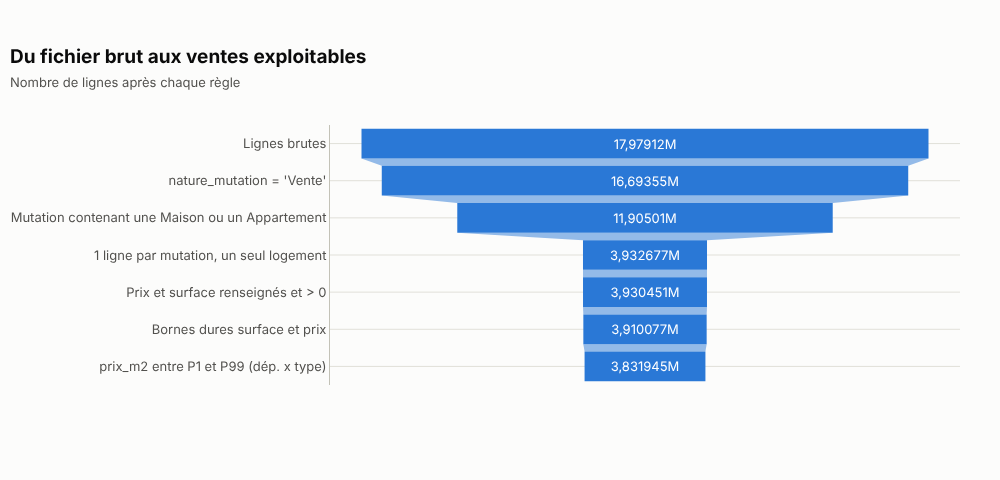

In [9]:
fig = go.Figure(go.Funnel(
    y=["Lignes brutes"] + report["description"].tolist(),
    x=[report.loc[0, "rows_before"]] + report["rows_after"].tolist(),
    marker={"color": az.SEQ_MID}, textinfo="value",
))
az.base_layout(fig, "Du fichier brut aux ventes exploitables", "Nombre de lignes après chaque règle", height=480)
fig.update_layout(margin={"l": 330})
fig.show()

## 4. Données nettoyées

In [10]:
df = pd.read_parquet(ROOT / "data" / "processed" / "ventes_clean.parquet")
print(f"{fr(len(df))} ventes, {fr(df['code_commune'].nunique())} communes")
df[["valeur_fonciere", "surface_reelle_bati", "prix_m2", "nombre_pieces_principales", "surface_terrain"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

3 831 945 ventes, 27 329 communes


,count,mean,std,min,1%,25%,50%,75%,99%,max
valeur_fonciere,3 831 945.0,246 585.4,237 810.7,10 000.0,30 000.0,120 000.0,190 000.0,297 725.0,1 140 000.0,17 000 000.0
surface_reelle_bati,3 831 945.0,81.9,42.6,9.0,18.0,53.0,76.0,101.0,220.0,1 000.0
prix_m2,3 831 945.0,3 270.1,2 390.8,125.0,459.5,1 734.4,2 653.1,4 015.6,12 342.9,42 719.2
nombre_pieces_principales,3 831 945.0,3.5,1.5,0.0,1.0,2.0,3.0,4.0,8.0,198.0
surface_terrain,3 831 945.0,1 231.5,12 742.2,0.0,0.0,0.0,114.0,693.0,15 615.0,9 483 843.0


In [11]:
df.isna().mean().mul(100).round(2).loc[lambda s: s > 0].rename("% manquant").to_frame()

,% manquant
longitude,1.2
latitude,1.2
code_ville,83.3
ville_principale,83.3


Seules les coordonnées manquent parfois (parcelles non géocodées) : sans effet sur les prix, ces
ventes sont simplement absentes de la carte.

### Distribution du prix au m²

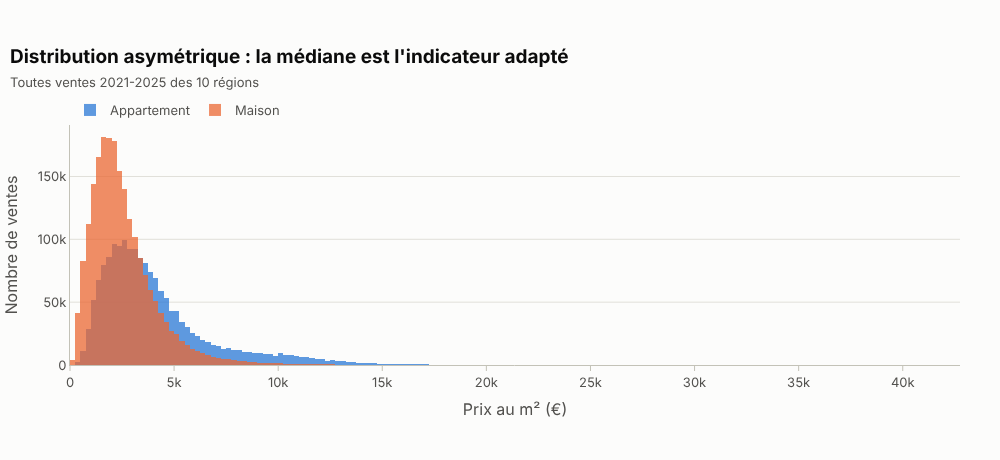

In [12]:
fig = go.Figure()
for typ, color in (("Appartement", az.CATEGORICAL[0]), ("Maison", az.CATEGORICAL[1])):
    fig.add_trace(go.Histogram(x=df.loc[df["type_local"] == typ, "prix_m2"], name=typ,
                               marker_color=color, opacity=0.75, xbins={"size": 250}))
fig.update_layout(barmode="overlay")
fig.update_xaxes(title="Prix au m² (€)")
fig.update_yaxes(title="Nombre de ventes")
az.base_layout(fig, "Distribution asymétrique : la médiane est l'indicateur adapté",
               "Toutes ventes 2021-2025 des 10 régions", height=460)
fig.show()

In [13]:
(df.groupby("type_local")["prix_m2"].agg(["mean", "median"])
   .assign(ecart_moyenne_mediane_pct=lambda t: (t["mean"] / t["median"] - 1) * 100))

,mean,median,ecart_moyenne_mediane_pct
type_local,,,
Appartement,4 138.3,3 388.1,22.1
Maison,2 575.9,2 210.7,16.5


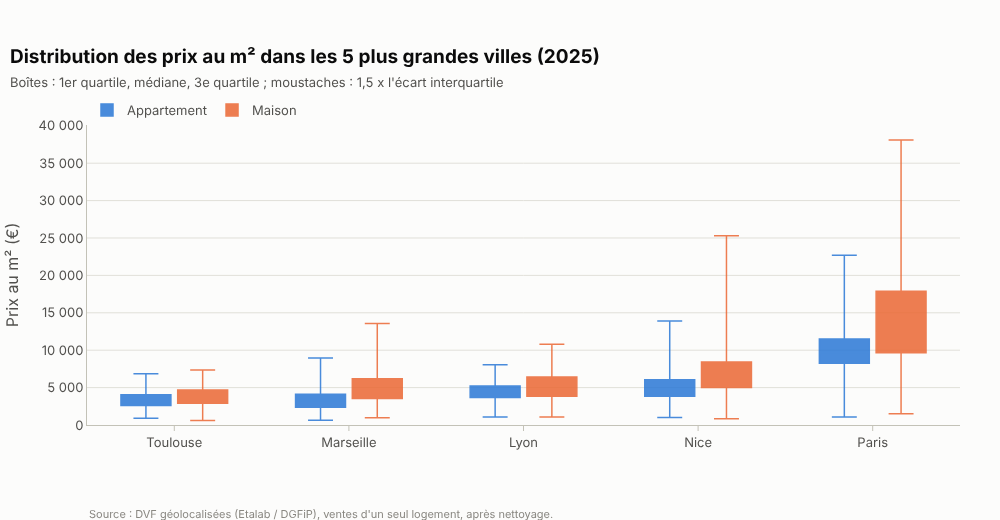

In [14]:
last = int(df["annee"].max())
az.fig_distribution(df, metropoles, last).show()

## 5. Prix et volumes dans le temps

In [15]:
yearly_all = df.groupby("annee").agg(nb_ventes=("prix_m2", "size"), prix_m2_median=("prix_m2", "median"))
yearly_all["evol_volume_pct"] = yearly_all["nb_ventes"].pct_change() * 100
yearly_all["evol_prix_pct"] = yearly_all["prix_m2_median"].pct_change() * 100
yearly_all

,nb_ventes,prix_m2_median,evol_volume_pct,evol_prix_pct
annee,,,,
2021,918513,2 516.7,NaN,NaN
2022,879404,2 730.8,-4.3,8.5
2023,691720,2 723.1,-21.3,-0.3
2024,628032,2 623.0,-9.2,-3.7
2025,714276,2 690.7,13.7,2.6


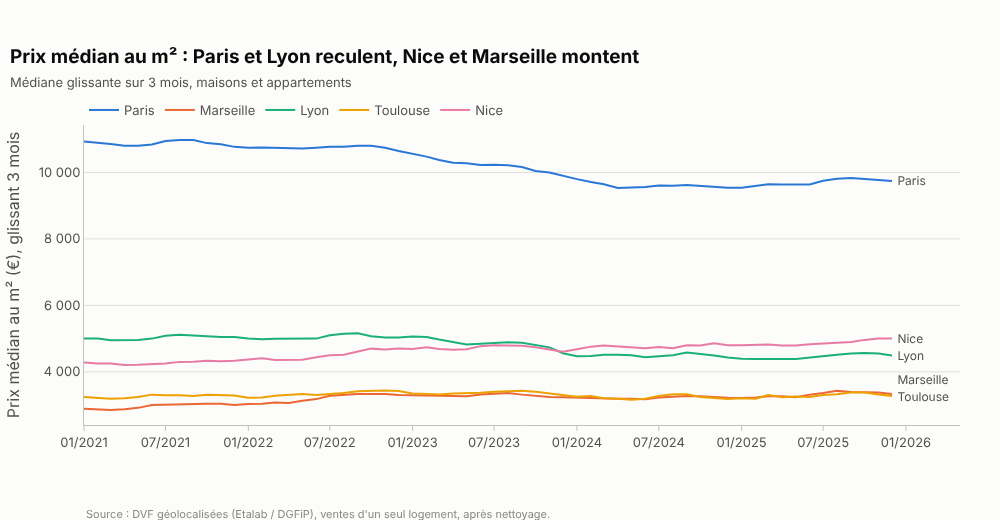

In [16]:
monthly = az.city_monthly(df)
az.fig_monthly_price(monthly, metropoles).show()

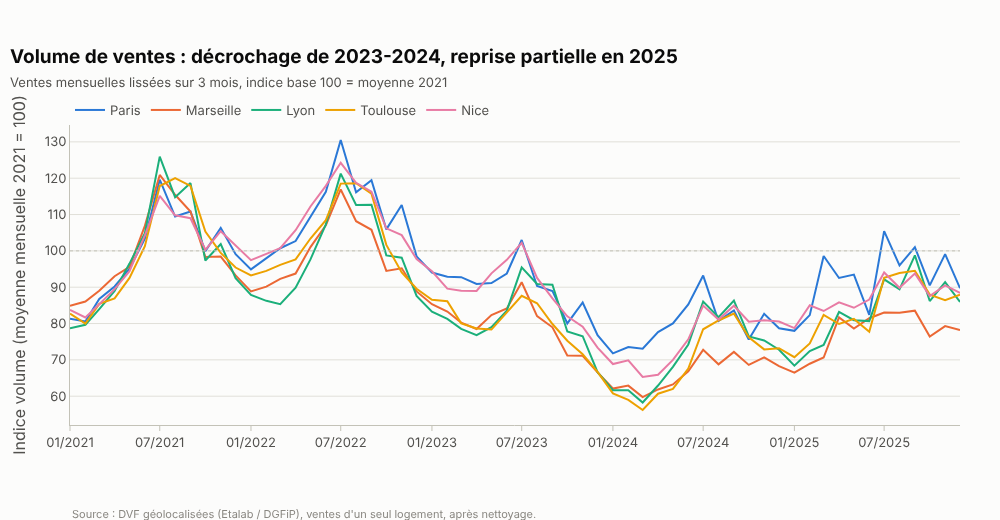

In [17]:
az.fig_monthly_volume(monthly, metropoles, int(df["annee"].min())).show()

## 6. Effet de la hausse des taux

On compare 2021 (taux bas) à 2023 (taux au plus haut) : variation du nombre de ventes et du prix
médian au m², ville par ville.

In [18]:
yearly = az.city_yearly(df)
effect = az.rate_rise_effect(yearly, 2021, 2023, last)
effect[["ville_principale", "evol_volume_hausse_taux_pct", "evol_prix_hausse_taux_pct",
        "evol_volume_total_pct", "evol_prix_total_pct"]]

,ville_principale,evol_volume_hausse_taux_pct,evol_prix_hausse_taux_pct,evol_volume_total_pct,evol_prix_total_pct
0,Angers,-32.4,8.3,-22.6,4.7
1,Argenteuil,-31.2,-2.1,-32.8,-5.6
2,Villeurbanne,-30.5,-1.4,-31.5,-8.3
3,Le Mans,-27.4,11.3,-22.7,11.6
4,Brest,-24.9,12.8,-23.8,16.0
5,Nantes,-24.1,-2.7,-22.7,-11.5
6,Le Havre,-23.9,7.9,-23.3,2.7
7,Reims,-23.6,6.1,-23.9,7.1
8,Lille,-22.9,3.5,-22.2,0.4
9,Toulouse,-22.6,3.0,-14.4,1.1


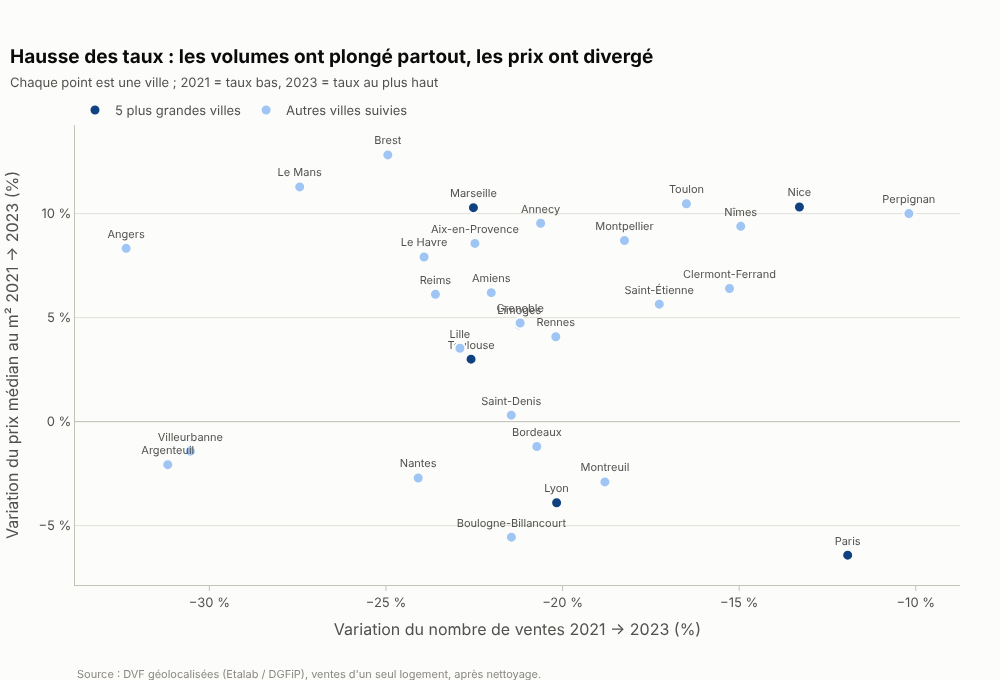

In [19]:
az.fig_rate_effect(effect, 2021, 2023, metropoles).show()

## 7. Test statistique : les prix 2025 diffèrent-ils de 2021 ?

Test de Mann-Whitney U (non paramétrique, adapté à des distributions asymétriques), par ville,
avec correction de Bonferroni pour le nombre de tests. La taille d'effet est la corrélation
rang-bisérielle *r* (> 0 : prix plus élevés en 2025).

In [20]:
tests = az.price_tests(df, 2021, last, cfg["analysis"]["alpha"], cfg["analysis"]["min_sales_for_test"])
tests.loc[tests["type_local"] == "Ensemble",
          ["ville_principale", "mediane_2021", f"mediane_{last}", "evol_mediane_pct",
           "p_value", "significatif", "r_rang_biseriel", "taille_effet"]]

,ville_principale,mediane_2021,mediane_2025,evol_mediane_pct,p_value,significatif,r_rang_biseriel,taille_effet
1,Aix-en-Provence,4 687.5,4 942.9,5.4,0.0,True,0.1,faible
4,Amiens,2 241.9,2 349.3,4.8,0.0,False,0.1,négligeable
7,Angers,3 000.0,3 139.5,4.7,0.0,True,0.1,négligeable
10,Annecy,4 764.7,5 185.2,8.8,0.0,True,0.1,faible
13,Argenteuil,3 622.5,3 420.6,-5.6,0.0,True,-0.1,négligeable
16,Bordeaux,4 752.1,4 269.2,-10.2,0.0,True,-0.2,faible
19,Boulogne-Billancourt,9 375.0,8 300.0,-11.5,0.0,True,-0.3,moyen
22,Brest,1 914.9,2 222.2,16.0,0.0,True,0.3,faible
25,Clermont-Ferrand,2 086.9,2 147.4,2.9,0.0,False,0.0,négligeable
28,Grenoble,2 558.6,2 515.6,-1.7,0.0,False,-0.0,négligeable


In [21]:
for text in tests.loc[tests["type_local"] == "Ensemble", "interpretation"]:
    print("-", text)

- Aix-en-Provence : prix au m² plus élevés en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 55 % de chances d'être plus chère au m² qu'une vente 2021.
- Amiens : pas de différence statistiquement significative entre 2021 et 2025 (p < 0,001, seuil corrigé 0,0006).
- Angers : prix au m² plus élevés en 2025 qu'en 2021 (p < 0,001 ; effet négligeable). Une vente 2025 prise au hasard a 54 % de chances d'être plus chère au m² qu'une vente 2021.
- Annecy : prix au m² plus élevés en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 57 % de chances d'être plus chère au m² qu'une vente 2021.
- Argenteuil : prix au m² plus bas en 2025 qu'en 2021 (p < 0,001 ; effet négligeable). Une vente 2025 prise au hasard a 45 % de chances d'être plus chère au m² qu'une vente 2021.
- Bordeaux : prix au m² plus bas en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 40 % de chances d'être plus chère au m² qu'une vente 2021.
- B

Avec plusieurs milliers de ventes par ville, de petits écarts deviennent significatifs : la
**taille d'effet** (négligeable ou faible presque partout, moyenne seulement à Boulogne-Billancourt)
rappelle que les évolutions, réelles, restent modérées à l'échelle d'une transaction individuelle.

## 8. Accessibilité

In [22]:
afford = az.affordability(yearly, cfg["analysis"]["budgets"], last)
(afford[afford["type_local"] == "Appartement"]
   .pivot(index="ville_principale", columns="budget", values="m2_achetables")
   .sort_values(150000, ascending=False)
   .round(0))

budget,150000,250000,350000
ville_principale,,,
Saint-Étienne,125.0,209.0,292.0
Limoges,99.0,166.0,232.0
Perpignan,99.0,165.0,231.0
Le Mans,78.0,130.0,182.0
Clermont-Ferrand,71.0,118.0,166.0
Brest,69.0,116.0,162.0
Nîmes,69.0,115.0,160.0
Le Havre,68.0,114.0,159.0
Amiens,61.0,101.0,142.0


In [23]:
ratio = az.income_ratio(yearly, df, last)
ratio

,ville_principale,prix_median,revenu_menage_median,annees_de_revenu
0,Saint-Étienne,73 000.0,27 542.0,2.7
1,Limoges,90 000.0,28 026.0,3.2
2,Le Mans,125 000.0,30 365.0,4.1
3,Clermont-Ferrand,120 000.0,28 230.0,4.3
4,Perpignan,105 000.0,24 633.0,4.3
5,Grenoble,133 000.0,30 907.0,4.3
6,Brest,139 000.0,29 647.0,4.7
7,Le Havre,139 000.0,29 412.0,4.7
8,Nîmes,132 000.0,27 423.0,4.8
9,Amiens,140 000.0,28 156.0,5.0


## 9. À retenir

* Les fichiers DVF ne sont pas « une ligne = une vente » : la déduplication par mutation et le
  comptage des logements distincts sont indispensables.
* Le marché s'est ajusté **par les volumes** (-25 % de ventes entre 2021 et 2023 sur les 10
  régions) bien plus que par les prix, dont la médiane a continué de monter sur le périmètre.
* Les grandes métropoles les plus chères (Paris, Lyon, Nantes, Bordeaux, Boulogne-Billancourt)
  reculent d'environ 10 % en euros courants ; la Méditerranée (Nice, Toulon, Marseille) et Brest
  progressent de 12 à 16 %.

Les constats chiffrés complets sont dans `reports/findings.md`.